## Auricle: A Multimodal Wearable Sensing Dataset for Cardiovascular and Hemodynamic Assessment

### Code to Reproduce Tables and Figures

Code is organized by section and subsection. It relies on the Auricle dataset which can be found on PhysioNet (https://physionet.org/content/auricle/1.0.0/).

### Setup

Install the required packages:

`python -m pip install numpy pandas scipy wfdb matplotlib seaborn statsmodels scikit-learn ipython`

In the first code cell, set `DATASET_ROOT` to the downloaded Auricle dataset root (the folder containing `RECORDS`, `demographics.csv`, and `data/`). The default points to `../auricle`. 

**This cell is expected to take a few minutes to run** as it processes the raw signal waveforms and extracts features for analysis. All processing code for both cardiac cycle-based and fixed length window-based processing can be found in the PulseKit folder.

In [12]:
# Required third-party packages: numpy, pandas, scipy, wfdb, matplotlib, seaborn,
# statsmodels, scikit-learn, and ipython. Install them with:
#     python -m pip install numpy pandas scipy wfdb matplotlib seaborn statsmodels scikit-learn ipython
from pathlib import Path
import os
import sys
import warnings

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib import gridspec
from scipy.stats import pearsonr
import wfdb

# Locate the PulseKit repository and set the Auricle dataset location here.
REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "PulseKit").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Could not find the repository folder containing PulseKit/.")

# Edit this path if the downloaded Auricle dataset is stored elsewhere.
DATASET_ROOT = Path(os.environ.get("AURICLE_DATASET_ROOT", REPO_ROOT / "auricle")).expanduser().resolve()
if not (DATASET_ROOT / "RECORDS").is_file() or not (DATASET_ROOT / "data").is_dir():
    raise FileNotFoundError(
        f"Expected an Auricle dataset root containing RECORDS and data/: {DATASET_ROOT}"
    )
DATA_DIR = DATASET_ROOT / "data"
PAPER_DIR = Path(__file__).resolve().parent if "__file__" in globals() else REPO_ROOT / "Auricle Dataset Paper"
OUT_DIR = PAPER_DIR  # Save reproduced figures and tables directly beside this notebook.
OUT_DIR.mkdir(exist_ok=True, parents=True)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from PulseKit import Dataset, ECG, PPG, Stethoscope, Earbud, Accelerometer, BP, Hemodynamics, Session
from PulseKit.signal_processors.base_signal import PhysiologicalSignal
from PulseKit.signal_processors.signal_processing_utils import apply_butterworth_filter

FS = 1000
QUALITY_THRESHOLD = 0.65
WINDOW_FILE = "segments_fixed_windows_length_10_overlap_0.5.csv"
CYCLE_FILE = "segments_cardiac_cycles_reference_signal_name_ecg.csv"

# Read signals by WFDB channel name through PulseKit's session loader; copy arrays
# before unloading so they remain usable by the plotting cells.
def load_wfdb_channels(session_id, channel_names):
    processors = [PhysiologicalSignal(name=name) for name in channel_names]
    session = Session(session_id, processors, str(DATASET_ROOT))
    try:
        channels = {}
        for name in channel_names:
            data = session.get_channel(name)
            if data is None:
                raise KeyError(f"Channel {name} is not present in record {session_id}")
            channels[name] = np.array(data, copy=True)
        return channels, float(session.header.fs)
    finally:
        session.unload_session()


def participant_id(session):
    parts = str(session).split("_")
    return parts[1] if len(parts) > 1 else str(session)


def cohort_name(session):
    return "Heart failure" if str(session).startswith("HFC_") else "Healthy"


def quality_score(series):
    """Convert SQI values and validity flags to numeric scores."""
    def is_bool(value):
        return isinstance(value, (bool, np.bool_))

    bool_true = series.map(lambda value: is_bool(value) and bool(value))
    bool_false = series.map(lambda value: is_bool(value) and not bool(value))
    text = series.astype("string").str.strip().str.lower()
    result = pd.to_numeric(series, errors="coerce")
    result = result.mask(bool_true | text.eq("true"), 1.0)
    result = result.mask(bool_false | text.eq("false"), np.nan)
    return result


# Check sampling frequency from an available WFDB header.
record_entries = [line.strip().replace("\\", "/") for line in (DATASET_ROOT / "RECORDS").read_text().splitlines() if line.strip() and not line.lstrip().startswith("#")]
first_record = next((DATA_DIR / entry for entry in record_entries if (DATA_DIR / entry).with_suffix(".hea").is_file()), None)
if first_record is None:
    raise FileNotFoundError(f"No local WFDB headers were found under {DATA_DIR}.")
FS = float(wfdb.rdheader(str(first_record)).fs)

# Generate required PulseKit segment CSVs only when absent. These are analysis
# intermediates saved beside each session's WFDB files; figures/tables go to OUT_DIR.
GENERATE_MISSING_SEGMENTS = True
SEGMENT_SIGNALS = [
    "ECG", "PPG_Finger", "PPG_Ear", "Digital_Stethoscope", "Earbud_Left", "Earbud_Right",
    "Accelerometer_Z", "Diastolic_BP", "Systolic_BP", "Mean_BP", "Heart_Rate",
    "Stroke_Volume", "Cardiac_Output", "SVR", "NIBP",
]
SIGNAL_PROCESSORS = [
    ECG("ECG"), PPG("PPG_Finger"), PPG("PPG_Ear"), Stethoscope("Digital_Stethoscope"),
    Earbud("Earbud_Left"), Earbud("Earbud_Right"), Accelerometer("Accelerometer_Z"),
    BP("Diastolic_BP"), BP("Systolic_BP"), PPG("NIBP"), Hemodynamics("Mean_BP"),
    Hemodynamics("Heart_Rate"), Hemodynamics("Stroke_Volume"),
    Hemodynamics("Cardiac_Output"), Hemodynamics("SVR"),
]
STRATEGIES = {
    "cycles":  (CYCLE_FILE,    lambda ds: ds.get_cardiac_cycles(reference_signal_name="ECG")),
    "fixed10": (WINDOW_FILE,   lambda ds: ds.get_fixed_windows(length=10, overlap=0.5)),
}

LOCAL_SESSION_IDS = Dataset._discover_session_ids(str(DATASET_ROOT))

if GENERATE_MISSING_SEGMENTS:
    dataset = Dataset(
        datasetName="Auricle paper reproduction",
        sessionIds=LOCAL_SESSION_IDS,
        signals=SIGNAL_PROCESSORS,
        data_directory=str(DATASET_ROOT),
    )

    for kind, (filename, segment_fn) in STRATEGIES.items():
        if all((DATA_DIR / s / filename).is_file() for s in LOCAL_SESSION_IDS):
            print(f"[{kind}] all sessions already segmented, skipping.")
            continue

        segment_fn(dataset)      
        dataset.process_signals(signal_list=SEGMENT_SIGNALS) 

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
HEMO_TARGETS = ["Diastolic_BP", "Systolic_BP", "Mean_BP", "Heart_Rate", "Stroke_Volume", "Cardiac_Output", "SVR"]
HEMO_LABELS = {
    "Diastolic_BP": ("Diastolic BP", "mmHg"), "Systolic_BP": ("Systolic BP", "mmHg"),
    "Mean_BP": ("Mean BP", "mmHg"), "Heart_Rate": ("Heart rate", "beats/min"),
    "Stroke_Volume": ("Stroke volume", "mL"), "Cardiac_Output": ("Cardiac output", "L/min"),
    "SVR": ("Systemic vascular resistance", "dyn·s/cm^5"),
}
SIGNAL_COLORS = {
    "ECG": "#E6194B", "PPG_Finger": "#3CB44B", "PPG_Ear": "#BFEF45",
    "Digital_Stethoscope": "#FFE119", "Accelerometer_Z": "#469990",
    "Earbud_Left": "#911EB4", "Earbud_Right": "#F032E6",
}
SIGNAL_LABELS = {
    "ECG": "ECG", "PPG_Finger": "Finger PPG", "PPG_Ear": "Ear PPG",
    "Digital_Stethoscope": "Digital stethoscope", "Accelerometer_Z": "SCG (Z-axis)",
    "Earbud_Left": "Left earbud", "Earbud_Right": "Right earbud",
}
HEMO_MAPPING = {
    "Diastolic_BP": ("Diastolic BP", "mmHg"), "Systolic_BP": ("Systolic BP", "mmHg"),
    "Mean_BP": ("Mean BP", "mmHg"), "Heart_Rate": ("Heart Rate", "BPM"),
    "Stroke_Volume": ("Stroke Volume", "mL"), "Cardiac_Output": ("Cardiac Output", "L/min"),
    "SVR": ("Systemic Vascular Resistance", r"dyn$\cdot$s/cm$^5$"),
}
HEMO_COLORS = {
    "Diastolic_BP": "#000075", "Systolic_BP": "#800000", "Mean_BP": "#9A6324",
    "Heart_Rate": "#808000", "Stroke_Volume": "#005A32", "Cardiac_Output": "#4B0082",
    "SVR": "#A52A2A", "NIBP": "#2F4F4F",
}

Signal SVR is not present in WFDB record HC_1_1.
Signal SVR is not present in WFDB record HC_1_2.
Signal SVR is not present in WFDB record HC_2_1.
Signal SVR is not present in WFDB record HC_2_2.
Signal SVR is not present in WFDB record HC_3_1.
Signal SVR is not present in WFDB record HC_3_2.
Signal SVR is not present in WFDB record HC_5_1.
Signal SVR is not present in WFDB record HC_6_1.
Signal SVR is not present in WFDB record HC_7_1.
[cycles] all sessions already segmented, skipping.
[fixed10] all sessions already segmented, skipping.


In [13]:
# preloading 10s windows 
window_paths = sorted(DATA_DIR.glob(f"*/{WINDOW_FILE}"))
if not window_paths:
    raise FileNotFoundError(f"No {WINDOW_FILE} files were found or generated under {DATA_DIR}.")
window_frames = []
for csv_path in window_paths:
    session = csv_path.parent.name
    frame = pd.read_csv(csv_path)
    frame["Session"] = session
    frame["Participant"] = participant_id(session)
    frame["Cohort"] = cohort_name(session)
    window_frames.append(frame)
all_windows = pd.concat(window_frames, ignore_index=True, sort=False)
print(f"Using Auricle data at {DATASET_ROOT}")
print(f"Loaded {len(window_paths)} session files and {len(all_windows):,} 10-second windows at {FS:g} Hz.")

Using Auricle data at /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/auricle
Loaded 107 session files and 40,692 10-second windows at 1000 Hz.


### Figures and Tables by Paper Section

### 2. Methods

#### 2.1 Participants

Table 1: Demographics Table

In [15]:
demographics = pd.read_csv(DATASET_ROOT / "demographics.csv")
demographics["Participant"] = pd.to_numeric(demographics["Participant"], errors="coerce")
demographics["Cohort"] = np.where(demographics["Participant"] >= 100, "Heart failure", "Healthy")
# Support current Auricle metadata names as well as older releases.
demographics = demographics.rename(columns={"Height (cm)": "Height", "Weight (kg)": "Weight"})
for col in ["Age", "Height", "Weight"]:
    demographics[col] = pd.to_numeric(demographics[col], errors="coerce")
demographics["LVEF_numeric"] = pd.to_numeric(
    demographics["LV ejection fraction"].astype(str).str.replace("%", "", regex=False),
    errors="coerce",
)


def mean_sd(values, digits=1):
    values = pd.to_numeric(values, errors="coerce").dropna()
    if values.empty:
        return "NA"
    return f"{values.mean():.{digits}f} ± {values.std():.{digits}f}"


demo_rows = []
for group in ["Healthy", "Heart failure"]:
    data = demographics.loc[demographics["Cohort"] == group].copy()
    female_n = data["Gender"].astype(str).str.lower().eq("female").sum()
    nyha = data["NYHA Class"].astype(str).str.strip()
    nyha_valid = nyha[nyha.isin(["1", "2", "3", "4"])]
    nyha_counts = nyha_valid.value_counts().sort_index()
    nyha_text = "; ".join(f"{level}: {count}" for level, count in nyha_counts.items())
    n_invalid = len(data) - len(nyha_valid)
    if not nyha_text:
        nyha_text = "N/A"
    elif n_invalid:
        nyha_text += f"; N/A: {n_invalid}"
    demo_rows.append({
        "Cohort": group,
        "Participants, n": data["Participant"].nunique(),
        "Age, years": mean_sd(data["Age"]),
        "Female, n (%)": f"{female_n} ({100 * female_n / max(len(data), 1):.1f}%)",
        "Height, cm": mean_sd(data["Height"]),
        "Weight, kg": mean_sd(data["Weight"]),
        "LVEF, %": mean_sd(data["LVEF_numeric"]),
        "NYHA class, n": nyha_text,
    })
demographics_table = pd.DataFrame(demo_rows).set_index("Cohort")
demographics_table.to_csv(OUT_DIR / "table_1_demographics.csv")
print("Table 1. Cohort demographics (continuous values are mean ± SD).")
display(demographics_table)
print(f"Saved: {OUT_DIR / 'table_1_demographics.csv'}")

Table 1. Cohort demographics (continuous values are mean ± SD).


,"Participants, n","Age, years","Female, n (%)","Height, cm","Weight, kg","LVEF, %","NYHA class, n"
Cohort,,,,,,,
Healthy,42,27.4 ± 9.5,21 (50.0%),171.0 ± 9.2,71.4 ± 16.9,NA,N/A
Heart failure,28,51.2 ± 15.1,8 (28.6%),170.1 ± 10.6,82.9 ± 19.9,39.5 ± 13.0,1: 13; 2: 8; 3: 3; 4: 1; N/A: 3


Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/table_1_demographics.csv


#### 2.2 Hardware Description

Figure 1: Anatomical sensor placement diagram with example signal clip

/var/folders/qj/v5vpz3c169506rzn5tfshb0h0000gn/T/ipykernel_21586/2559961251.py:113: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


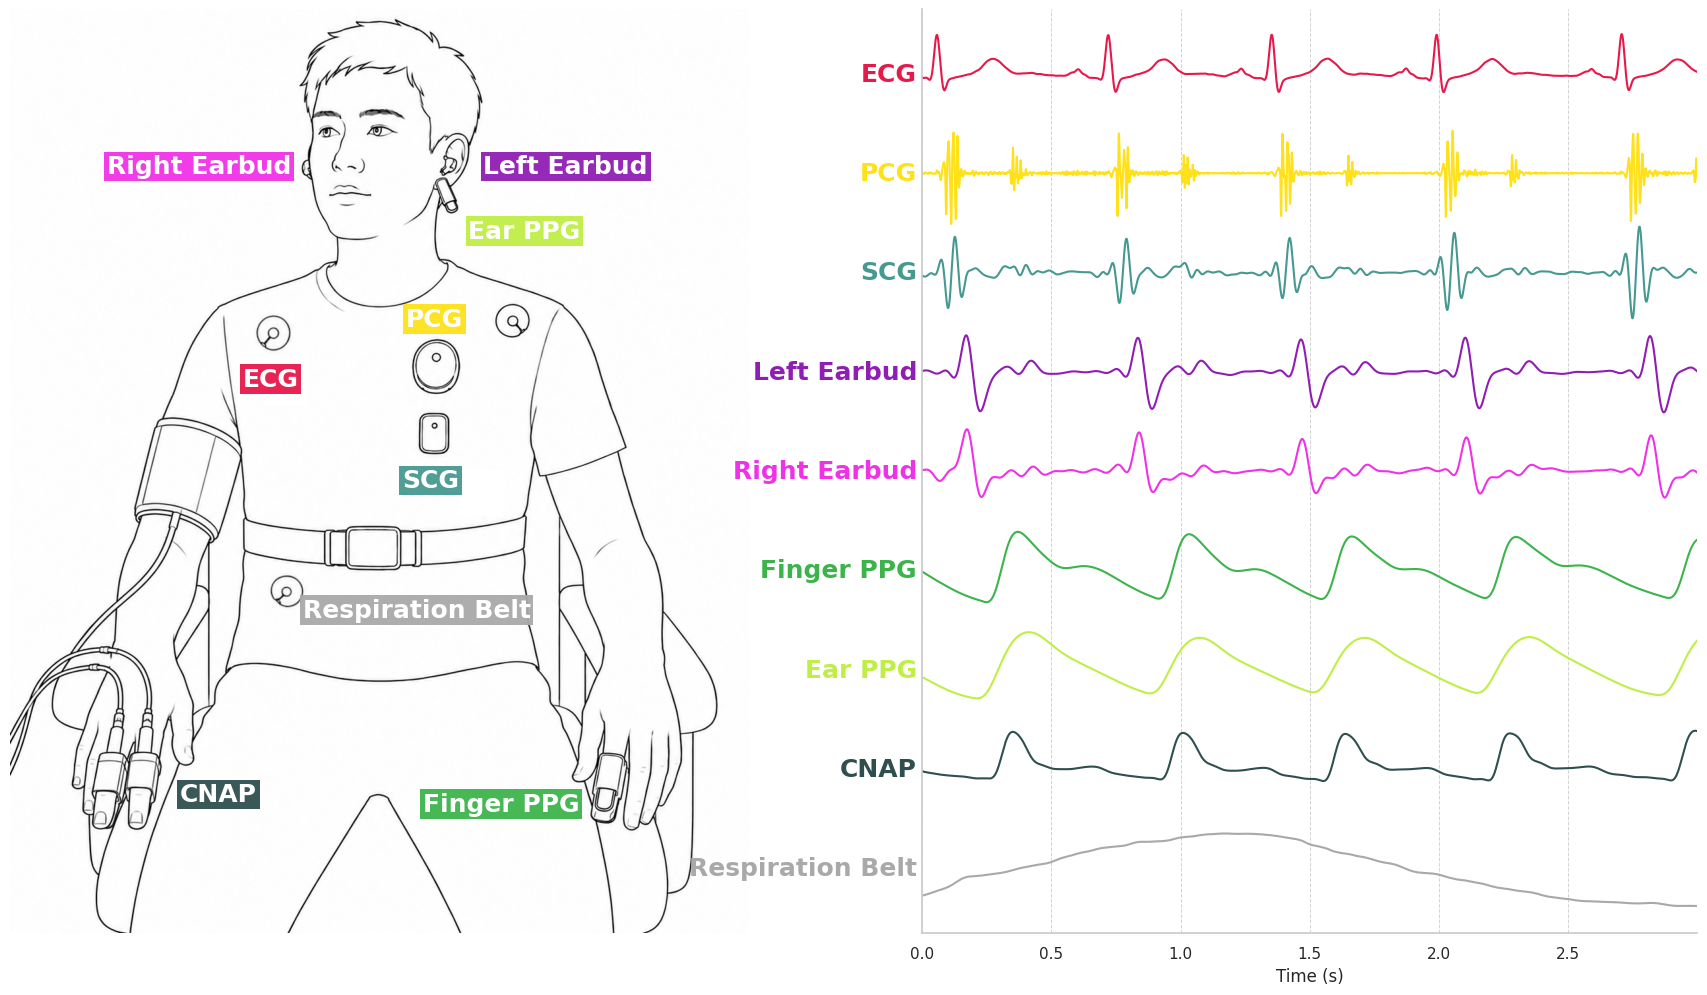

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_1_sensors.png


In [18]:
TARGET_SESSION = "HC_10_2"
TARGET_WINDOW_ID = 58
DISPLAY_SECONDS = 3
CLIP_OFFSET_SECONDS = 3
TRACE_SCALE = 0.75
TRACE_SPACING = 2.0
MODALITY_DATA = {
    "ECG": {"signal": "ECG"}, "PCG": {"signal": "Digital_Stethoscope"},
    "SCG": {"signal": "Accelerometer_Z"}, "Left Earbud": {"signal": "Earbud_Left"},
    "Right Earbud": {"signal": "Earbud_Right"}, "Finger PPG": {"signal": "PPG_Finger"},
    "Ear PPG": {"signal": "PPG_Ear"}, "CNAP": {"signal": "NIBP"},
    "Respiration Belt": {"signal": "Respiration_Belt"},
}
MODALITY_COLORS = {
    "ECG": "#E6194B", "PCG": "#FFE119", "SCG": "#469990", "Left Earbud": "#911EB4",
    "Right Earbud": "#F032E6", "Finger PPG": "#3CB44B", "Ear PPG": "#BFEF45",
    "CNAP": "#2F4F4F", "Respiration Belt": "#A9A9A9",
}
SENSOR_IMAGE_LABEL_POSITIONS = {
    "PCG": (0.315, 0.665), "ECG": (0.61, 0.60), "SCG": (0.31, 0.49),
    "Left Earbud": (0.42, 0.83), "Right Earbud": (0.60, 0.83),
    "Finger PPG": (0.99, 0.14), "Ear PPG": (0.40, 0.76), "CNAP": (0.01, 0.15),
    "Respiration Belt": (0.33, 0.35),
}
SENSOR_IMAGE_LABEL_ALIGNMENTS = {
    "PCG": "left", "ECG": "right", "SCG": "left", "Left Earbud": "left",
    "Right Earbud": "right", "Finger PPG": "right", "Ear PPG": "left",
    "CNAP": "left", "Respiration Belt": "center",
}
FILTER_SETTINGS = {
    "ECG": (0.5, 40.0), "Digital_Stethoscope": (40.0, 240.0),
    "Accelerometer_Z": (0.8, 25.0), "Earbud_Left": (0.5, 15.0),
    "Earbud_Right": (0.5, 15.0), "PPG_Finger": (0.5, 15.0),
    "PPG_Ear": (0.5, 15.0), "NIBP": (0.5, 15.0), "Respiration_Belt": None,
}

session_dir = DATA_DIR / TARGET_SESSION
fixed_df = pd.read_csv(session_dir / FIXED_30_FILE)
quality_row = fixed_df.loc[fixed_df["window_id"].eq(TARGET_WINDOW_ID)]
if quality_row.empty:
    raise ValueError(f"Window {TARGET_WINDOW_ID} not found in {TARGET_SESSION}.")
selection_signals = ["ECG", "Digital_Stethoscope", "Accelerometer_Z", "Earbud_Left", "Earbud_Right", "PPG_Finger", "PPG_Ear"]
quality_columns = [f"{name}_quality" for name in selection_signals if f"{name}_quality" in fixed_df]
minimum_quality = pd.to_numeric(quality_row.iloc[0][quality_columns], errors="coerce").min()
SAMPLING_RATE = FS
window_start = int(quality_row.iloc[0]["start"])
clip_start = window_start + int(CLIP_OFFSET_SECONDS * SAMPLING_RATE)
clip_end = min(int(quality_row.iloc[0]["end"]), clip_start + int(DISPLAY_SECONDS * SAMPLING_RATE))
time_vector = (np.arange(clip_start, clip_end) - clip_start) / SAMPLING_RATE


def load_filtered_trace(raw, signal_name):
    raw = np.asarray(raw, dtype=float).squeeze()
    settings = FILTER_SETTINGS[signal_name]
    if settings is None:
        return raw
    lowcut, highcut = settings
    filtered = apply_butterworth_filter(raw, lowcut, "high", SAMPLING_RATE, order=5)
    filtered = apply_butterworth_filter(filtered, highcut, "low", SAMPLING_RATE, order=5)
    return filtered if np.ptp(filtered) > 0 else raw


def normalize_trace(trace):
    trace = np.asarray(trace, dtype=float)
    finite = trace[np.isfinite(trace)]
    if not len(finite):
        return np.zeros_like(trace)
    trace = np.nan_to_num(trace - np.median(finite))
    amplitude = np.percentile(np.abs(trace), 99)
    return trace / amplitude if amplitude > 0 else trace


channel_names = [config["signal"] for config in MODALITY_DATA.values()]
channels, session_fs = load_wfdb_channels(TARGET_SESSION, channel_names)
if not np.isclose(session_fs, SAMPLING_RATE):
    raise ValueError(f"Sample rate mismatch: configured {SAMPLING_RATE:g} Hz, record has {session_fs:g} Hz")
cycle_data = {}
for modality, config in MODALITY_DATA.items():
    signal_name = config["signal"]
    filtered = load_filtered_trace(channels[signal_name], signal_name)
    cycle_data[modality] = normalize_trace(filtered[clip_start:clip_end])
available_modalities = [name for name in MODALITY_DATA if name in cycle_data]

fig = plt.figure(figsize=(22, 12), dpi=100)
grid = fig.add_gridspec(1, 2, width_ratios=[1, 1], wspace=0.2)
ax_person, ax_signal = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])
ax_person.imshow(mpimg.imread(PAPER_DIR / "collection_diagram.png"))
ax_person.set_aspect("equal")
ax_person.set_xticks([])
ax_person.set_yticks([])
for spine in ax_person.spines.values():
    spine.set_visible(False)
ax_signal.set_yticks([])
ax_signal.spines["top"].set_visible(False)
ax_signal.spines["right"].set_visible(False)
for modality in available_modalities:
    x_pos, y_pos = SENSOR_IMAGE_LABEL_POSITIONS[modality]
    ax_person.text(x_pos + (0.22 if x_pos <= 0.5 else -0.22), y_pos, modality,
                   transform=ax_person.transAxes, color="white", fontsize=18,
                   fontweight="bold", ha=SENSOR_IMAGE_LABEL_ALIGNMENTS[modality], va="center",
                   bbox={"facecolor": MODALITY_COLORS[modality], "alpha": 0.95, "edgecolor": "none", "pad": 2})
for index, modality in enumerate(available_modalities):
    offset = -TRACE_SPACING * index
    ax_signal.plot(time_vector, cycle_data[modality] * TRACE_SCALE + offset,
                   color=MODALITY_COLORS[modality], linewidth=1.5, zorder=2)
    ax_signal.text(time_vector.min() - 0.02, offset, modality, color=MODALITY_COLORS[modality],
                   ha="right", va="center", fontweight="bold", fontsize=18)
ax_signal.set_xlabel("Time (s)")
ax_signal.set_xlim(time_vector.min(), time_vector.max())
ax_signal.set_ylim(-(len(available_modalities) - 1) * TRACE_SPACING - TRACE_SPACING * 0.65, TRACE_SPACING * 0.65)
ax_signal.set_yticks([])
ax_signal.grid(axis="x", color="lightgrey", linestyle="--", linewidth=0.7)
fig.tight_layout()
fig.savefig(OUT_DIR / "figure_1_sensors.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_DIR / 'figure_1_sensors.png'}")

### 4. Technical Validation

#### 4.1 Distribution of Hemodynamic Parameters

Figure 3: Hemodynamic distributions by cohort

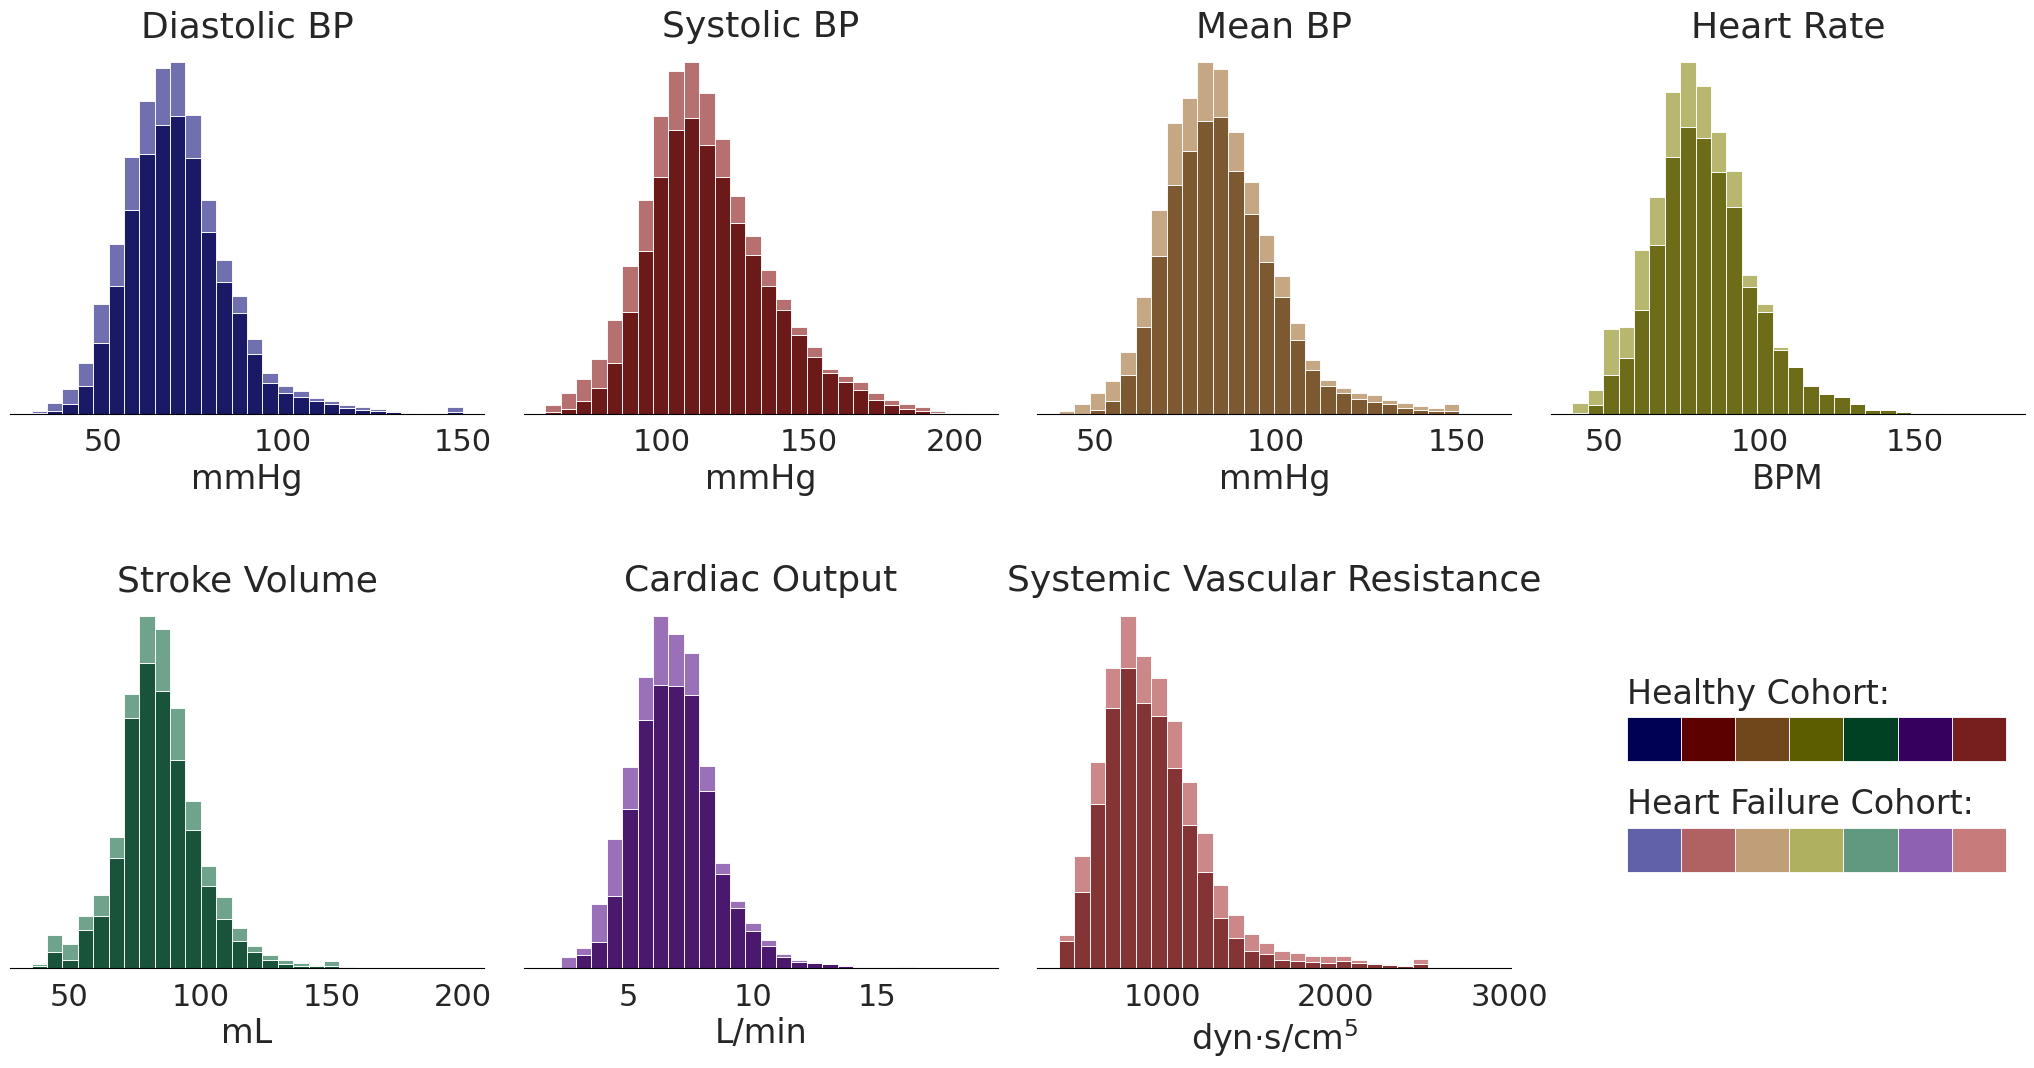

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_3_hemodynamics.png


In [19]:
PHYSIOLOGICAL_VALID_RANGES = {
    "Diastolic_BP": (30, 150), "Systolic_BP": (60, 250), "Mean_BP": (40, 180),
    "Heart_Rate": (40, 180), "Stroke_Volume": (20, 200),
    "Cardiac_Output": (1.5, 19), "SVR": (400, 2900),
}

cycle_files = sorted(DATA_DIR.glob(f"*/{CYCLE_FILE}"))
if not cycle_files:
    raise FileNotFoundError(f"No cardiac-cycle CSVs found under {DATA_DIR}.")

cycle_frames = []
for path in cycle_files:
    cohort = "Heart Failure" if path.parent.name.startswith("HFC_") else "Healthy"
    frame = pd.read_csv(path)
    if not {"Diastolic_BP_quality", "Systolic_BP_quality"}.issubset(frame.columns):
        continue
    bp_valid = frame["Diastolic_BP_quality"].isin([True, "True", "true", 1, 1.0]) & frame["Systolic_BP_quality"].isin([True, "True", "true", 1, 1.0])
    value_cols = [f"{name}_midpoint" for name in HEMO_TARGETS if f"{name}_midpoint" in frame.columns]
    if not value_cols:
        continue
    part = frame.loc[bp_valid, value_cols].copy()
    part["Group"] = cohort
    cycle_frames.append(part)

if not cycle_frames:
    raise ValueError("No valid hemodynamic cycle measurements available.")
hemo_df = pd.concat(cycle_frames, ignore_index=True)
midpoint_cols = [f"{target}_midpoint" for target in HEMO_TARGETS if f"{target}_midpoint" in hemo_df.columns]
hemo_targets = [col.replace("_midpoint", "") for col in midpoint_cols]
target_colors = [HEMO_COLORS[target] for target in hemo_targets]

def make_shades(hex_color):
    rgb = np.array(plt.matplotlib.colors.to_rgb(hex_color))
    return np.clip(rgb * 0.72, 0, 1), np.clip(1 - (1 - rgb) * 0.62, 0, 1)

fig = plt.figure(figsize=(26, 12), facecolor="white")
gs = fig.add_gridspec(nrows=2, ncols=12, hspace=0.5, wspace=0.3)
axes = [fig.add_subplot(gs[0, 0:3]), fig.add_subplot(gs[0, 3:6]), fig.add_subplot(gs[0, 6:9]),
        fig.add_subplot(gs[0, 9:12]), fig.add_subplot(gs[1, 0:3]), fig.add_subplot(gs[1, 3:6]),
        fig.add_subplot(gs[1, 6:9])]
legend_ax = fig.add_subplot(gs[1, 9:12])
legend_ax.axis("off")

for i, (col, target_name) in enumerate(zip(midpoint_cols, hemo_targets)):
    ax = axes[i]
    ax.set_facecolor("white")
    ax.grid(False)
    clean_title, unit = HEMO_MAPPING.get(target_name, (target_name.replace("_", " "), "Units"))
    healthy_vals = pd.to_numeric(hemo_df.loc[hemo_df["Group"] == "Healthy", col], errors="coerce").dropna()
    hf_vals = pd.to_numeric(hemo_df.loc[hemo_df["Group"] == "Heart Failure", col], errors="coerce").dropna()
    if target_name in PHYSIOLOGICAL_VALID_RANGES:
        min_val, max_val = PHYSIOLOGICAL_VALID_RANGES[target_name]
        healthy_vals = healthy_vals[(healthy_vals >= min_val) & (healthy_vals <= max_val)]
        hf_vals = hf_vals[(hf_vals >= min_val) & (hf_vals <= max_val)]
    combined = pd.concat([healthy_vals, hf_vals], ignore_index=True)
    if combined.empty:
        ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes, fontsize=22)
        ax.set_title(clean_title, fontsize=26, fontweight="semibold")
        ax.set_xlabel(unit, fontsize=22)
    else:
        dark_shade, light_shade = make_shades(target_colors[i])
        ax.hist([healthy_vals, hf_vals], bins=28, stacked=True,
                color=[dark_shade, light_shade], alpha=0.9, edgecolor="white", linewidth=0.7)
        ax.set_title(clean_title, fontsize=26)
        ax.set_xlabel(unit, fontsize=24)
    ax.set_ylabel("")
    ax.set_yticks([])
    ax.tick_params(axis="y", left=False, labelleft=False)
    ax.tick_params(axis="x", labelsize=22)
    for side in ("left", "top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("black")
    ax.spines["bottom"].set_linewidth(0.8)

dark_shades = [make_shades(color)[0] for color in target_colors]
light_shades = [make_shades(color)[1] for color in target_colors]
x0, bar_h, bar_w = 0.16, 0.12, 0.8
seg_w = bar_w / max(len(target_colors), 1)
y_light, y_dark = 0.26, 0.56
for j, (dark, light) in enumerate(zip(dark_shades, light_shades)):
    xj = x0 + j * seg_w
    legend_ax.add_patch(plt.Rectangle((xj, y_dark), seg_w, bar_h, transform=legend_ax.transAxes, facecolor=dark, edgecolor="white", linewidth=0.6))
    legend_ax.add_patch(plt.Rectangle((xj, y_light), seg_w, bar_h, transform=legend_ax.transAxes, facecolor=light, edgecolor="white", linewidth=0.6))
legend_ax.text(x0, y_dark + bar_h + 0.02, "Healthy Cohort:", transform=legend_ax.transAxes, ha="left", va="bottom", fontsize=24)
legend_ax.text(x0, y_light + bar_h + 0.02, "Heart Failure Cohort:", transform=legend_ax.transAxes, ha="left", va="bottom", fontsize=24)
fig.savefig(OUT_DIR / "figure_3_hemodynamics.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {OUT_DIR / 'figure_3_hemodynamics.png'}")

Table 2: Hemodynamic parameters across activities

In [20]:
PHYSIOLOGICAL_VALID_RANGES = {
    "Diastolic_BP": (30, 150), "Systolic_BP": (60, 250), "Mean_BP": (40, 200),
    "Heart_Rate": (40, 180), "Stroke_Volume": (20, 200),
    "Cardiac_Output": (1.5, 19), "SVR": (400, 2900),
}


def build_hemodynamic_activity_summary(data_dir):
    csv_files = sorted(data_dir.glob(f"*/{CYCLE_FILE}"))

    hemodynamics = [
        "Diastolic_BP", "Systolic_BP", "Mean_BP",
        "Heart_Rate", "Stroke_Volume", "Cardiac_Output", "SVR"
    ]
    midpoint_cols = [f"{sig}_midpoint" for sig in hemodynamics]

    activity_labels = {
        0: "rest",
        1: "breath_hold",
        2: "valsalva",
        3: "exercise",
        4: "cold_pressor",
        9: "setup",
    }
    ordered_activities = [
        "rest", "breath_hold", "valsalva", "exercise", "cold_pressor", "setup", "unknown", "invalid_interval"
    ]
    display_activities = {"rest": "Rest", "breath_hold": "Breath Hold", "valsalva": "Valsalva", "exercise": "Exercise", "cold_pressor": "Cold Pressor"}
    hemo_labels = {
        "Diastolic_BP": "Diastolic BP (mmHg)", "Systolic_BP": "Systolic BP (mmHg)",
        "Mean_BP": "Mean BP (mmHg)", "Heart_Rate": "Heart Rate (BPM)",
        "Stroke_Volume": "Stroke Volume (mL)", "Cardiac_Output": "Cardiac Output (L/min)",
        "SVR": "Systemic Vascular Resistance (dyn·s/cm⁵)",
    }

    all_sessions = []

    for file in csv_files:
        try:
            session_name = file.parent.name

            if "HFC" in session_name:
                group = "Heart Failure"
            elif "HC" in session_name:
                group = "Healthy"
            else:
                group = "Unknown"

            df = pd.read_csv(file)

            if "Diastolic_BP_quality" not in df.columns or "Systolic_BP_quality" not in df.columns:
                continue

            # Only windows where both BP qualities are valid.
            d_valid = df["Diastolic_BP_quality"].isin([True, "True", "true", 1, 1.0])
            s_valid = df["Systolic_BP_quality"].isin([True, "True", "true", 1, 1.0])
            df = df[d_valid & s_valid].copy()

            if df.empty:
                continue

            available_cols = [col for col in midpoint_cols if col in df.columns]
            if not available_cols:
                continue

            for base_col in hemodynamics:
                col = f"{base_col}_midpoint"
                if col in df.columns:
                    df[col] = pd.to_numeric(df[col], errors="coerce")
                    df.loc[df[col] <= 1, col] = np.nan
                    min_val, max_val = PHYSIOLOGICAL_VALID_RANGES[base_col]
                    df.loc[(df[col] < min_val) | (df[col] > max_val), col] = np.nan

            # Activity association using majority label inside each window interval.
            try:
                channel, _ = load_wfdb_channels(session_name, ["Activity_Annotations"])
                mask = np.nan_to_num(np.asarray(channel["Activity_Annotations"], dtype=float).squeeze()).round().astype(int)
            except (FileNotFoundError, ValueError, KeyError):
                mask = None

            if mask is not None:
                def get_activity_label(row):
                    start_idx = int(row.get("start", 0))
                    end_idx = int(row.get("end", len(mask)))
                    start_idx = max(0, start_idx)
                    end_idx = min(len(mask), end_idx)

                    if start_idx < end_idx:
                        beat_mask = mask[start_idx:end_idx]
                        if len(beat_mask) == 0:
                            return "invalid_interval"
                        majority_code = np.bincount(beat_mask).argmax()
                        return activity_labels.get(majority_code, "unknown")

                    return "invalid_interval"

                df["activity"] = df.apply(get_activity_label, axis=1)
            else:
                df["activity"] = "unknown"

            extracted = df[available_cols + ["activity"]].copy()
            extracted["Group"] = group
            extracted["Session"] = session_name
            extracted["Participant"] = participant_id(session_name)
            all_sessions.append(extracted)

        except Exception as e:
            print(f"Error processing {file}: {e}")

    if not all_sessions:
        print("No valid hemodynamic data found.")
        return None

    master_df = pd.concat(all_sessions, ignore_index=True)
    master_df["Cohort"] = master_df["Group"].map({"Healthy": "Healthy", "Heart Failure": "Heart failure"})
    master_df["Activity"] = master_df["activity"].map(display_activities)

    # Per-participant means, per activity and overall
    long_parts = []
    for col in midpoint_cols:
        if col not in master_df.columns:
            continue
        target = col.replace("_midpoint", "")
        part = master_df[["Participant", "Session", "Cohort", "Activity", col]].rename(columns={col: "value"}).dropna(subset=["value"])
        part["Parameter"] = target
        by_act = part.dropna(subset=["Activity"]).groupby(["Participant", "Session", "Cohort", "Activity", "Parameter"], as_index=False)["value"].mean()
        overall = part.groupby(["Participant", "Session", "Cohort", "Parameter"], as_index=False)["value"].mean()
        overall["Activity"] = "Overall"
        long_parts.append(by_act)
        long_parts.append(overall)
    activity_long = pd.concat(long_parts, ignore_index=True)

    def fmt_mean_sd(series):
        return "-" if len(series) == 0 else f"{series.mean():.1f} ± {series.std():.1f}"

    activity_order = list(display_activities.values()) + ["Overall"]
    rows = [{"Parameter": "Healthy Cohort", **{a: "" for a in activity_order}}]
    for cohort_label, cohort_key in [("Healthy", "Healthy"), ("Heart Failure", "Heart failure")]:
        if cohort_key == "Heart failure":
            rows.append({"Parameter": "Heart Failure Cohort", **{a: "" for a in activity_order}})
        for sig in hemodynamics:
            row = {"Parameter": hemo_labels[sig]}
            for activity in activity_order:
                subset = activity_long[(activity_long["Parameter"] == sig) & (activity_long["Activity"] == activity)]
                text = fmt_mean_sd(subset.loc[subset["Cohort"].eq(cohort_key), "value"])
                if cohort_key == "Healthy" and activity == "Overall":
                    # Every individual cardiac cycle, with a random intercept per participant
                    cycles = master_df[["Participant", "Cohort", f"{sig}_midpoint"]].rename(columns={f"{sig}_midpoint": "value"}).dropna()
                    if cycles["Participant"].nunique() >= 4 and cycles.groupby("Cohort")["Participant"].nunique().min() >= 2:
                        try:
                            with warnings.catch_warnings():
                                warnings.simplefilter("ignore")
                                fit = smf.mixedlm("value ~ C(Cohort)", data=cycles, groups=cycles["Participant"]).fit(disp=False)
                            p_value = float(fit.pvalues.get("C(Cohort)[T.Heart failure]", np.nan))
                            text += " ***" if p_value < 0.001 else " **" if p_value < 0.01 else " *" if p_value < 0.05 else ""
                        except Exception as exc:
                            print(f"Mixed model skipped for {sig}: {exc}")
                row[activity] = text
            rows.append(row)
    return pd.DataFrame(rows)


summary_table_activity = build_hemodynamic_activity_summary(DATA_DIR)
summary_table_activity.to_csv(OUT_DIR / "table_2_hemodynamics.csv", index=False)
display(summary_table_activity)
print(f"Saved: {OUT_DIR / 'table_2_hemodynamics.csv'}")

Signal Activity_Annotations is not present in WFDB record HC_1_1.
Signal Activity_Annotations is not present in WFDB record HC_38_2.
Signal Activity_Annotations is not present in WFDB record HFC_108_1.
Signal Activity_Annotations is not present in WFDB record HFC_124_1.


,Parameter,Rest,Breath Hold,Valsalva,Exercise,Cold Pressor,Overall
0,Healthy Cohort,,,,,,
1,Diastolic BP (mmHg),69.5 ± 10.5,69.5 ± 11.8,70.8 ± 12.2,73.4 ± 13.1,71.6 ± 13.7,70.6 ± 10.2
2,Systolic BP (mmHg),116.0 ± 15.2,110.5 ± 16.0,110.0 ± 17.6,128.2 ± 20.0,116.2 ± 19.2,117.0 ± 14.9 **
3,Mean BP (mmHg),83.9 ± 11.1,81.6 ± 12.4,81.9 ± 13.0,89.6 ± 13.9,86.0 ± 14.2,84.8 ± 10.9
4,Heart Rate (BPM),79.4 ± 10.4,76.0 ± 9.4,81.3 ± 12.6,101.3 ± 13.4,80.4 ± 10.8,82.5 ± 10.4 ***
5,Stroke Volume (mL),85.8 ± 13.2,81.7 ± 12.9,78.0 ± 12.3,87.5 ± 16.3,84.1 ± 14.5,84.7 ± 12.8
6,Cardiac Output (L/min),6.8 ± 1.2,6.2 ± 1.0,6.2 ± 1.1,8.8 ± 1.9,6.7 ± 1.3,6.9 ± 1.2 **
7,Systemic Vascular Resistance (dyn·s/cm⁵),946.7 ± 251.6,997.8 ± 273.8,994.0 ± 292.7,791.7 ± 268.6,967.9 ± 251.4,936.6 ± 243.2 *
8,Heart Failure Cohort,,,,,,
9,Diastolic BP (mmHg),66.5 ± 17.2,67.5 ± 17.9,73.9 ± 18.0,68.9 ± 18.7,-,65.7 ± 15.8


Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/table_2_hemodynamics.csv


#### 4.2 Distribution of Physiological Signal Quality Index

Figure 4: Representative SQI thresholds

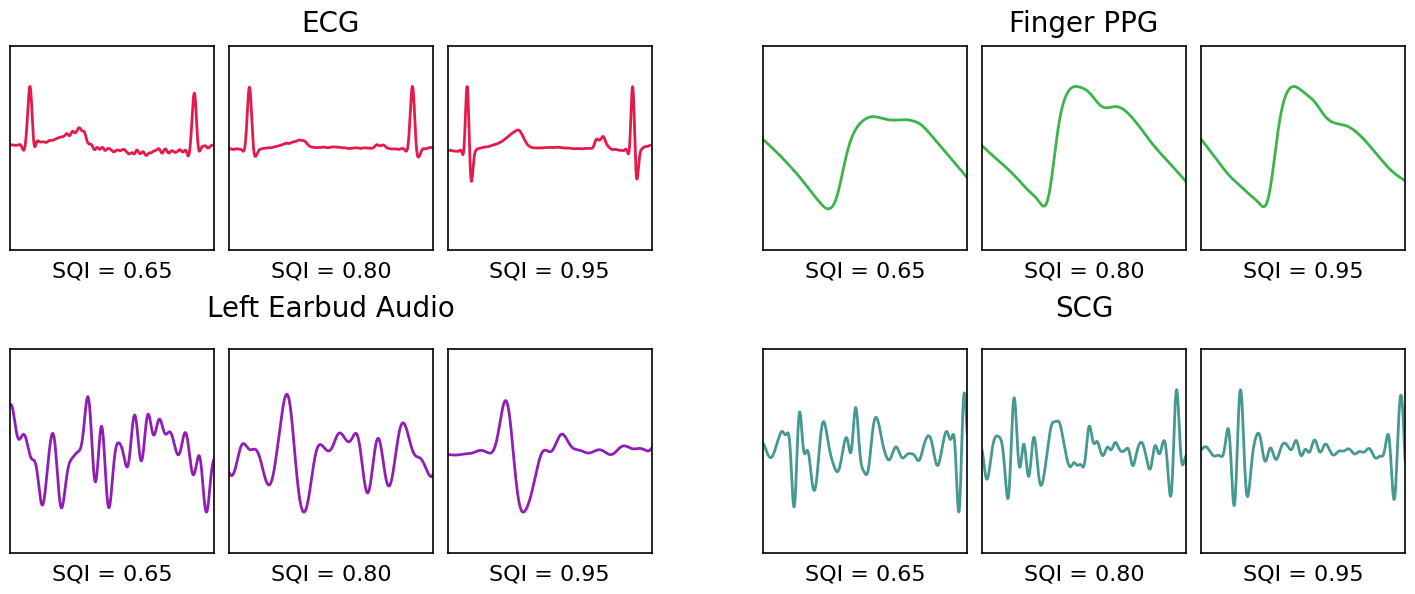

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_4_sqi_examples.png


In [21]:
MANUAL_CYCLE_SELECTIONS = {
    ("ECG", 0.65): ("HC_4_2", 117), ("ECG", 0.80): ("HC_8_2", 393), ("ECG", 0.95): ("HC_17", 249),
    ("PPG_Finger", 0.65): ("HC_3_2", 79), ("PPG_Finger", 0.80): ("HC_1_2", 225), ("PPG_Finger", 0.95): ("HC_8", 154),
    ("Earbud_Left", 0.65): ("HC_20_2", 142), ("Earbud_Left", 0.80): ("HC_15_2", 286), ("Earbud_Left", 0.95): ("HC_10_2", 108),
    ("Accelerometer_Z", 0.65): ("HC_33", 308), ("Accelerometer_Z", 0.80): ("HC_17", 124), ("Accelerometer_Z", 0.95): ("HC_37", 97),
}
EXAMPLE_SIGNALS = ["ECG", "PPG_Finger", "Earbud_Left", "Accelerometer_Z"]
EXAMPLE_DISPLAY_NAMES = {"ECG": "ECG", "PPG_Finger": "Finger PPG", "Earbud_Left": "Left Earbud Audio", "Accelerometer_Z": "SCG"}
SQI_THRESHOLDS = [0.65, 0.80, 0.95]
CONTEXT_SAMPLES = int(0.1 * FS)
WAVEFORM_SCALE = 0.6
EXAMPLE_FILTERS = {"ECG": (0.5, 40.0), "PPG_Finger": (0.5, 15.0), "Earbud_Left": (0.5, 15.0), "Accelerometer_Z": (0.8, 25.0)}


def resolve_session_id(session_name):
    if (DATA_DIR / session_name / f"{session_name}.hea").is_file():
        return session_name
    matches = sorted(path.name for path in DATA_DIR.glob(f"{session_name}_*") if path.is_dir() and (path / f"{path.name}.hea").is_file())
    return matches[0] if matches else None


cycle_csvs = sorted(DATA_DIR.glob(f"*/{CYCLE_FILE}"))


def middle_cycle_in_window(session_id, window_id):
    """Middle cardiac cycle whose window_id matches the 10 s window (original selection logic)."""
    cycle_path = DATA_DIR / session_id / CYCLE_FILE
    if not cycle_path.is_file():
        return None
    cycles = pd.read_csv(cycle_path)
    if not {"window_id", "start", "end"}.issubset(cycles.columns):
        return None
    cycles = cycles.loc[cycles["window_id"] == window_id].dropna(subset=["start", "end"])
    cycles = cycles.loc[cycles["end"] > cycles["start"]]
    if cycles.empty:
        return None
    cycle = cycles.iloc[len(cycles) // 2]
    return int(cycle["start"]), int(cycle["end"])


def find_sqi_cycle_at_threshold(signal, threshold):
    quality_col = f"{signal}_quality"
    best_match = None
    for window_path in sorted(DATA_DIR.glob(f"*/{WINDOW_FILE}")):
        session_id = window_path.parent.name
        if session_id.startswith("HFC_"):
            continue
        windows = pd.read_csv(window_path)
        if not {"window_id", quality_col}.issubset(windows.columns):
            continue
        quality = pd.to_numeric(windows[quality_col], errors="coerce")
        windows = windows.loc[quality >= threshold, ["window_id"]].copy()
        windows["_quality"] = quality.loc[windows.index]
        windows = windows.sort_values("_quality", key=lambda values: (values - threshold).abs())
        for _, window in windows.iterrows():
            cycle = middle_cycle_in_window(session_id, window["window_id"])
            if cycle is None:
                continue
            candidate = (session_id, cycle[0], cycle[1], float(window["_quality"]))
            if best_match is None or candidate[3] < best_match[3]:
                best_match = candidate
            break
    return best_match


def get_manual_cycle(signal, threshold):
    key = (signal, threshold)
    if key not in MANUAL_CYCLE_SELECTIONS:
        return find_sqi_cycle_at_threshold(signal, threshold)
    session_name, window_id = MANUAL_CYCLE_SELECTIONS[key]
    session_id = resolve_session_id(session_name)
    window_path = DATA_DIR / session_id / WINDOW_FILE if session_id else None
    if window_path is None or not window_path.is_file():
        return None
    windows = pd.read_csv(window_path)
    window_row = windows.loc[windows["window_id"] == window_id]
    quality_col = f"{signal}_quality"
    if window_row.empty or quality_col not in window_row.columns:
        return None
    cycle = middle_cycle_in_window(session_id, window_id)
    if cycle is None:
        return None
    quality = quality_score(window_row[quality_col].iloc[:1]).iloc[0]
    return session_id, cycle[0], cycle[1], float(quality)


def load_example_signal(session_id, signal):
    lowcut, highcut = EXAMPLE_FILTERS[signal]
    channels, sampling_rate = load_wfdb_channels(session_id, [signal])
    filtered = apply_butterworth_filter(np.asarray(channels[signal], dtype=float), lowcut, "high", sampling_rate, order=5)
    return apply_butterworth_filter(filtered, highcut, "low", sampling_rate, order=5)


def normalize_example_waveform(waveform):
    centered = waveform - np.median(waveform)
    amplitude = np.max(np.abs(centered))
    return WAVEFORM_SCALE * centered / amplitude if amplitude > 0 else centered


plt.rcParams.update({"font.family": "DejaVu Sans", "text.color": "black", "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"})
fig = plt.figure(figsize=(18, 7))
grid = gridspec.GridSpec(2, 7, width_ratios=[1, 1, 1, 0.4, 1, 1, 1], wspace=0.08, hspace=0.12)
axes = np.empty((2, 6), dtype=object)
for row in range(2):
    for col in range(6):
        axes[row, col] = fig.add_subplot(grid[row, col if col < 3 else col + 1])
filtered_cache = {}
for signal_idx, signal in enumerate(EXAMPLE_SIGNALS):
    row = signal_idx // 2
    col_offset = (signal_idx % 2) * len(SQI_THRESHOLDS)
    for threshold_idx, threshold in enumerate(SQI_THRESHOLDS):
        ax = axes[row, col_offset + threshold_idx]
        result = get_manual_cycle(signal, threshold)
        if result is None:
            ax.text(0.5, 0.5, f"No cycle ≥ {threshold:.2f}", ha="center", va="center", transform=ax.transAxes, fontsize=12, color="black")
            ax.set_ylim(-1, 1)
        else:
            session_id, start_idx, end_idx, quality = result
            cache_key = (session_id, signal)
            if cache_key not in filtered_cache:
                filtered_cache[cache_key] = load_example_signal(session_id, signal)
            filtered = filtered_cache[cache_key]
            left, right = max(0, start_idx - CONTEXT_SAMPLES), min(len(filtered), end_idx + CONTEXT_SAMPLES)
            waveform = normalize_example_waveform(filtered[left:right])
            ax.plot(np.arange(len(waveform)), waveform, color=SIGNAL_COLORS[signal], linewidth=2)
            ax.set_xlim(0, max(len(waveform) - 1, 1))
            ax.set_ylim(-1, 1)
            ax.margins(x=0, y=0)
        ax.set_box_aspect(1)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("black")
            spine.set_linewidth(1.2)
        ax.set_xlabel(f"SQI = {threshold:.2f}", fontsize=16, labelpad=8)
for signal_idx, signal in enumerate(EXAMPLE_SIGNALS):
    row = signal_idx // 2
    col_offset = (signal_idx % 2) * len(SQI_THRESHOLDS)
    left_ax, right_ax = axes[row, col_offset], axes[row, col_offset + len(SQI_THRESHOLDS) - 1]
    left_pos, right_pos = left_ax.get_position(), right_ax.get_position()
    fig.text((left_pos.x0 + right_pos.x1) / 2, left_pos.y1 + 0.02, EXAMPLE_DISPLAY_NAMES[signal], ha="center", va="bottom", fontsize=20, color="black")
fig.subplots_adjust(top=0.90, bottom=0.08, hspace=0.12, wspace=0.08)
fig.savefig(OUT_DIR / "figure_4_sqi_examples.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_DIR / 'figure_4_sqi_examples.png'}")

Figure 5: CDF of SQIs

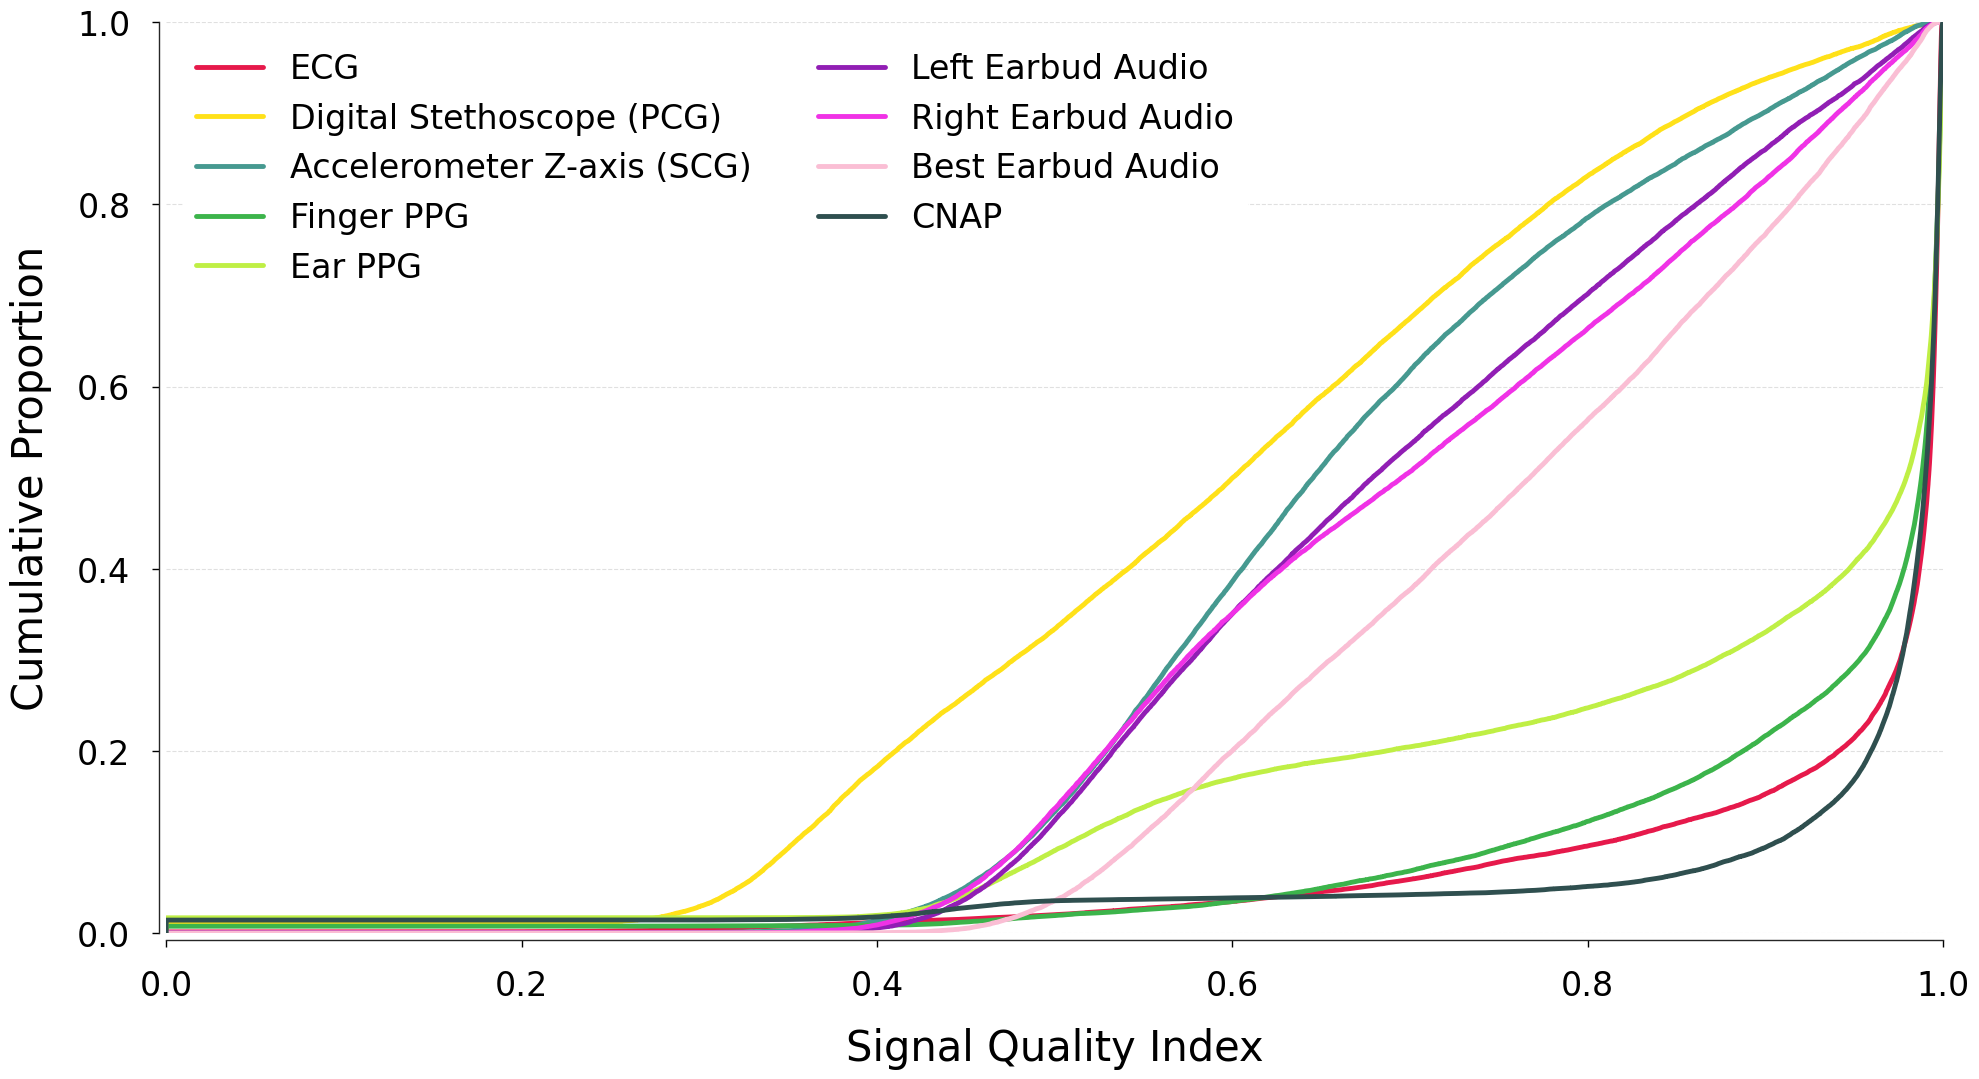

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_5_cdf_sqi.png


In [22]:
SQI_CDF_SIGNALS = [
    'ECG', 'Digital_Stethoscope', 'Accelerometer_Z', 'PPG_Finger', 'PPG_Ear',
    'Earbud_Left', 'Earbud_Right', 'Earbud_Best', 'NIBP',
]
SQI_CDF_COLORS = {
    **SIGNAL_COLORS, 'Earbud_Best': '#FABED4', 'NIBP': '#2F4F4F',
}
SQI_CDF_LABELS = {
    'ECG': 'ECG', 'Digital_Stethoscope': 'Digital Stethoscope (PCG)',
    'Accelerometer_Z': 'Accelerometer Z-axis (SCG)', 'PPG_Finger': 'Finger PPG',
    'PPG_Ear': 'Ear PPG', 'Earbud_Left': 'Left Earbud Audio',
    'Earbud_Right': 'Right Earbud Audio', 'Earbud_Best': 'Best Earbud Audio',
    'NIBP': 'CNAP',
}

sqi_master_df = pd.DataFrame({
    signal: quality_score(all_windows.get(f'{signal}_quality', pd.Series(dtype=float)))
    for signal in SQI_CDF_SIGNALS if signal != 'Earbud_Best'
})
if {'Earbud_Left', 'Earbud_Right'}.issubset(sqi_master_df.columns):
    sqi_master_df['Earbud_Best'] = sqi_master_df[['Earbud_Left', 'Earbud_Right']].max(axis=1)

sns.set_theme(style='ticks', context='paper', font_scale=1.4, font='DejaVu Sans')
plt.rcParams.update({'text.color': 'black', 'axes.labelcolor': 'black',
                      'xtick.color': 'black', 'ytick.color': 'black'})
fig, ax = plt.subplots(figsize=(20, 11))
for signal in SQI_CDF_SIGNALS:
    vals = sqi_master_df[signal].dropna().to_numpy() if signal in sqi_master_df.columns else np.array([])
    vals = vals[(vals >= 0) & (vals <= 1)]
    if len(vals) == 0:
        continue
    sorted_vals = np.sort(vals)
    cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
    ax.plot(sorted_vals, cdf, color=SQI_CDF_COLORS[signal], linewidth=3.5,
            label=SQI_CDF_LABELS[signal])
ax.set_xlabel('Signal Quality Index', fontsize=30, color='black', labelpad=18)
ax.set_ylabel('Cumulative Proportion', fontsize=30, color='black', labelpad=18)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.grid(axis='x', alpha=0)
ax.legend(frameon=True, framealpha=1.0, edgecolor='none', fontsize=24,
          ncol=2, loc='upper left', labelcolor='black')
ax.tick_params(axis='both', labelsize=24, pad=16, colors='black')
sns.despine(trim=True, offset=5)
fig.tight_layout()
fig.savefig(OUT_DIR / 'figure_5_cdf_sqi.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {OUT_DIR / "figure_5_cdf_sqi.png"}')

#### 4.3 Heart Rate Concordance

Figure 6: Correlation between HRs

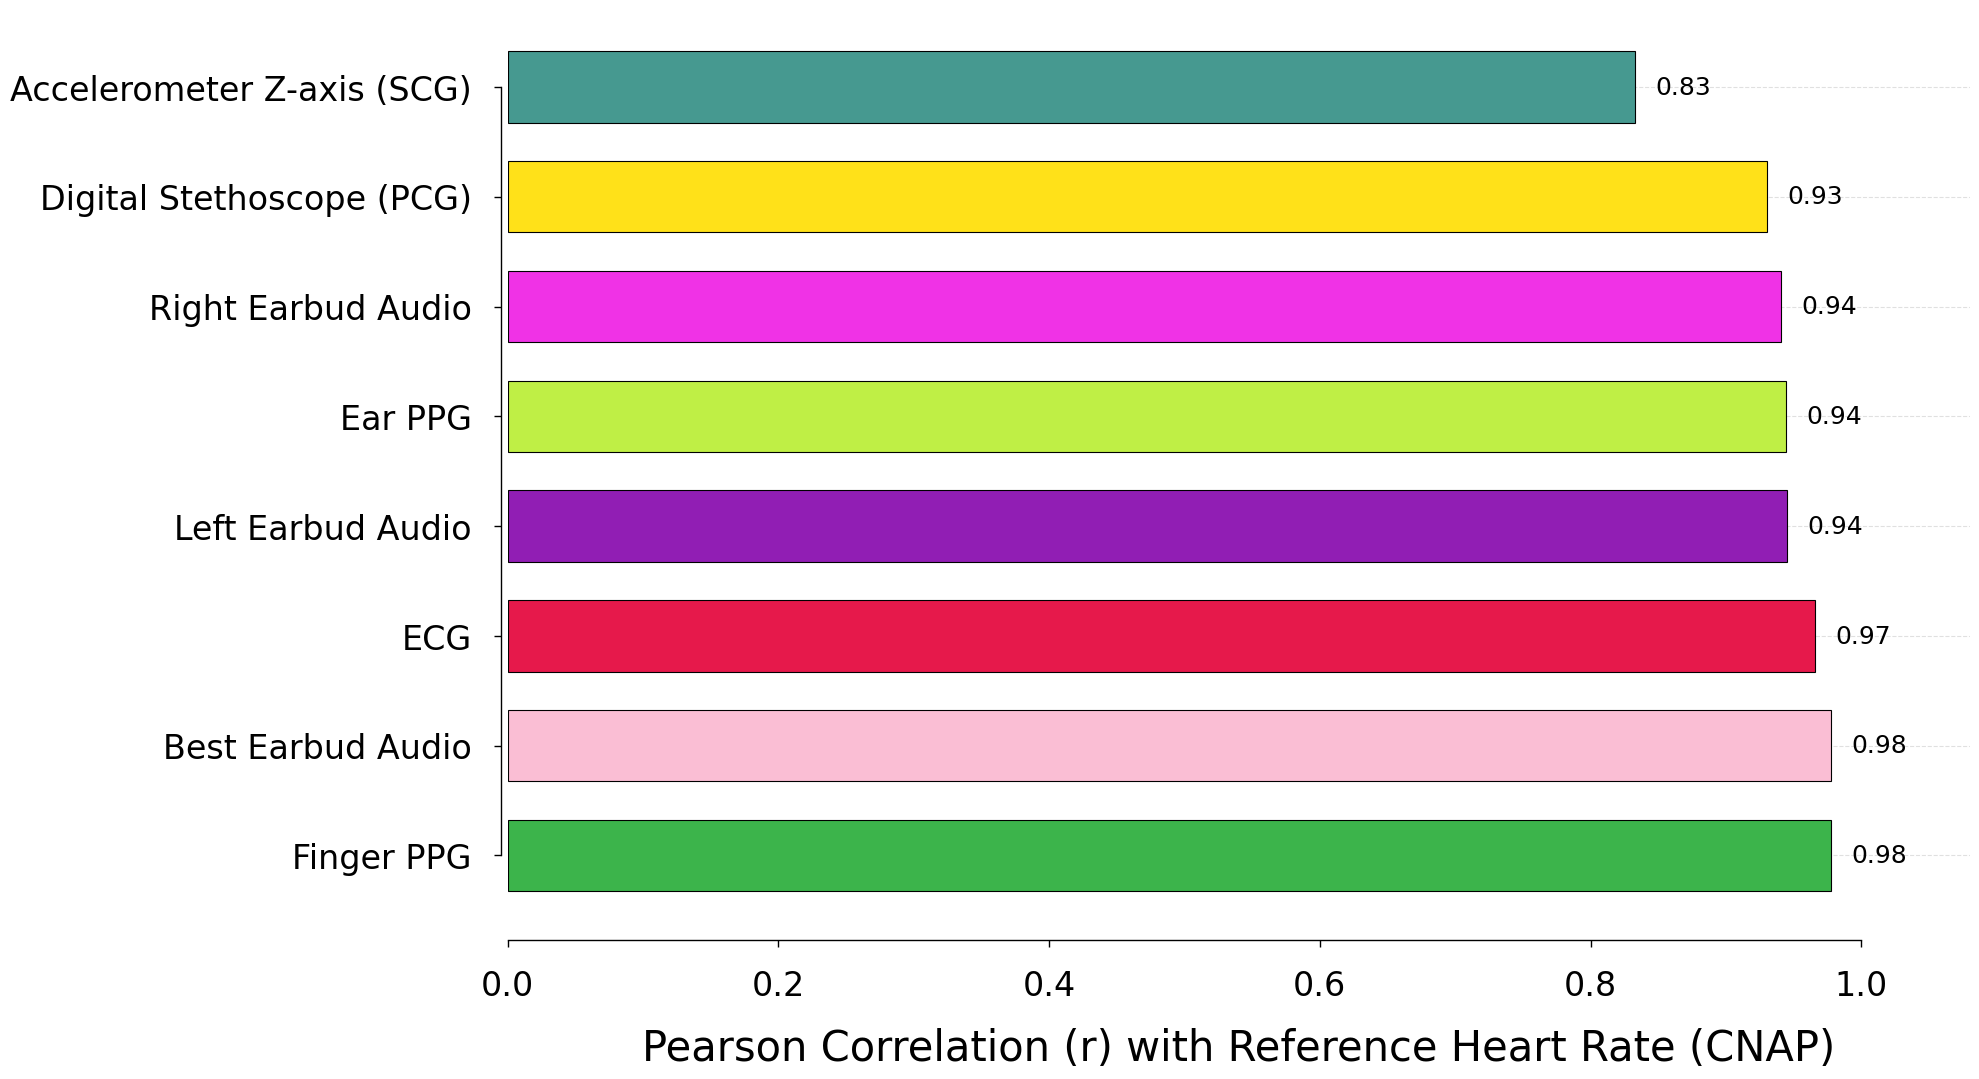

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_6_correlation_hr.png


In [35]:
HR_THRESHOLD = 0.65
PHYSIOLOGICAL_VALID_RANGES = {
    "Diastolic_BP": (30, 150), "Systolic_BP": (60, 250), "Mean_BP": (40, 200),
    "Heart_Rate": (40, 180), "Stroke_Volume": (20, 200),
    "Cardiac_Output": (1.5, 19), "SVR": (400, 2900),
}
HR_SIGNALS = ["ECG", "Digital_Stethoscope", "Accelerometer_Z", "PPG_Finger", "PPG_Ear", "Earbud_Left", "Earbud_Right", "Earbud_Best"]
HR_LABELS = {
    "ECG": "ECG", "Digital_Stethoscope": "Digital Stethoscope (PCG)",
    "Accelerometer_Z": "Accelerometer Z-axis (SCG)", "PPG_Finger": "Finger PPG",
    "PPG_Ear": "Ear PPG", "Earbud_Left": "Left Earbud Audio",
    "Earbud_Right": "Right Earbud Audio", "Earbud_Best": "Best Earbud Audio",
}
HR_COLORS = {
    "ECG": "#E6194B", "Digital_Stethoscope": "#FFE119",
    "Accelerometer_Z": "#469990", "PPG_Finger": "#3CB44B", "PPG_Ear": "#BFEF45",
    "Earbud_Left": "#911EB4", "Earbud_Right": "#F032E6", "Earbud_Best": "#FABED4",
}
hr_paths = sorted(DATA_DIR.glob(f"*/{WINDOW_FILE}"))
hr_pairs = {signal: [] for signal in HR_SIGNALS}
for path in hr_paths:
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        print(f"Skipping {path.parent.name}: {exc}")
        continue
    reference_col = "Heart_Rate_median"
    if not {reference_col, "Diastolic_BP_quality", "Systolic_BP_quality"}.issubset(frame.columns):
        continue
    reference_valid = frame["Diastolic_BP_quality"].isin([True, "True", "true", 1, 1.0]) & frame["Systolic_BP_quality"].isin([True, "True", "true", 1, 1.0])
    reference = pd.to_numeric(frame[reference_col], errors="coerce")
    hr_min, hr_max = PHYSIOLOGICAL_VALID_RANGES["Heart_Rate"]
    reference = reference.where(reference.between(hr_min, hr_max))

    def get_numeric_column(candidates):
        for name in candidates:
            if name in frame.columns:
                return pd.to_numeric(frame[name], errors="coerce")
        return pd.Series(np.nan, index=frame.index, dtype=float)

    left_hr = get_numeric_column(["Earbud_Left_HR_IBI", "Earbud_Left_HR"])
    right_hr = get_numeric_column(["Earbud_Right_HR_IBI", "Earbud_Right_HR"])
    left_quality = quality_score(frame.get("Earbud_Left_quality", pd.Series(np.nan, index=frame.index)))
    right_quality = quality_score(frame.get("Earbud_Right_quality", pd.Series(np.nan, index=frame.index)))
    left_error = (left_hr - reference).abs()
    right_error = (right_hr - reference).abs()
    use_left = left_hr.notna() & (right_hr.isna() | (left_error <= right_error))
    frame["Earbud_Best_HR"] = left_hr.where(use_left, right_hr)
    frame["Earbud_Best_quality"] = left_quality.where(use_left, right_quality)

    for signal in HR_SIGNALS:
        hr = get_numeric_column([f"{signal}_HR_IBI", f"{signal}_HR"])
        quality_col = f"{signal}_quality"
        if quality_col not in frame.columns:
            continue
        sqi = quality_score(frame[quality_col])
        valid = reference_valid & sqi.gt(HR_THRESHOLD) & reference.notna() & hr.notna()
        pair = pd.DataFrame({"reference": reference[valid], "estimate": hr[valid]})
        if not pair.empty:
            hr_pairs[signal].append(pair)

hr_rows = []
for signal, frames in hr_pairs.items():
    if not frames:
        continue
    pooled = pd.concat(frames, ignore_index=True)
    if len(pooled) < 2 or pooled["reference"].std() == 0 or pooled["estimate"].std() == 0:
        continue
    r_value, _ = pearsonr(pooled["estimate"], pooled["reference"])
    hr_rows.append({"signal": signal, "r": float(r_value), "n": len(pooled)})
if not hr_rows:
    raise ValueError("No valid 30-second sensor/CNAP heart-rate pairs were found in available WFDB records.")
hr_concordance = pd.DataFrame(hr_rows).sort_values("r", ascending=True).reset_index(drop=True)
hr_concordance["label"] = hr_concordance["signal"].map(HR_LABELS)

sns.set_theme(style="ticks", context="paper", font_scale=1.4, font="DejaVu Sans")
plt.rcParams.update({"text.color": "black", "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"})
fig, ax = plt.subplots(figsize=(20, 11))
y_positions = np.arange(len(hr_concordance))
r_values = hr_concordance["r"].to_numpy()
signals = hr_concordance["signal"].tolist()
ax.barh(y_positions, r_values, color=[HR_COLORS[signal] for signal in signals], edgecolor="black", linewidth=0.8, height=0.65)
for y, value in zip(y_positions, r_values):
    ax.text(value + 0.015, y, f"{value:.2f}", va="center", ha="left", fontsize=18, color="black")
ax.set_yticks(y_positions)
ax.set_yticklabels(hr_concordance["label"], fontsize=24)
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.set_xlabel("Pearson Correlation (r) with Reference Heart Rate (CNAP)", fontsize=30, color="black", labelpad=18)
ax.set_ylabel("", fontsize=30, color="black", labelpad=18)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.grid(axis="x", alpha=0)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="both", labelsize=24, pad=16, colors="black")
sns.despine(trim=True, offset=5)
fig.tight_layout()
fig.savefig(OUT_DIR / "figure_6_correlation_hr.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_DIR / 'figure_6_correlation_hr.png'}")

#### 4.4 Pulse Transit Time Concordance

Figure 7: PAT Distributions

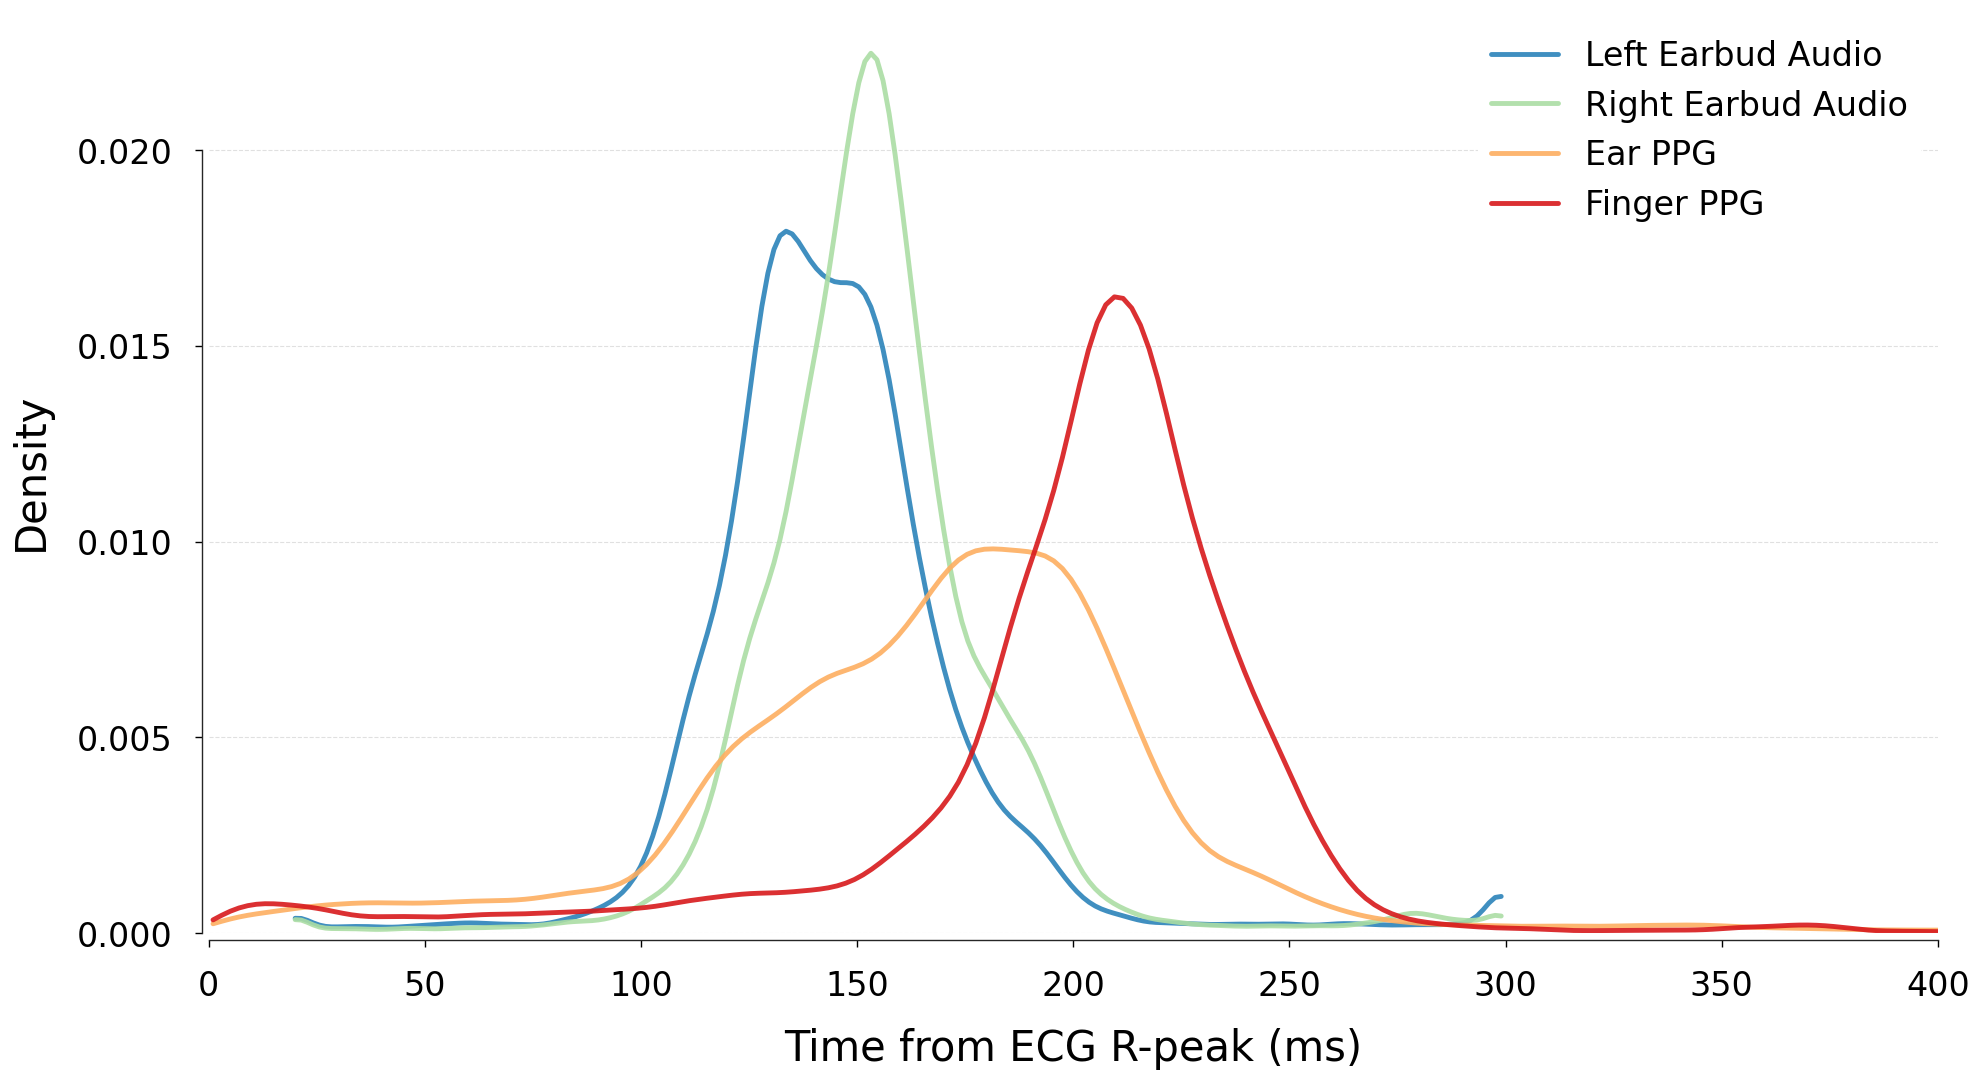

Saved: /Users/thomaskleinknecht/Desktop/BLOOD PRESSURE/pulsekit/Auricle Dataset Paper/figure_7_pat_distributions.png


In [24]:
PAT_THRESHOLD = 0.65
PAT_FS = FS
PAT_OUTPUT = OUT_DIR / "figure_7_pat_distributions.png"
PAT_COLUMNS = {
    "PTT_Earbud_Left_a": ("Earbud_Left_a", "Earbud_Left_quality", "Left Earbud Audio", "#2b83ba"),
    "PTT_Earbud_Right_a": ("Earbud_Right_a", "Earbud_Right_quality", "Right Earbud Audio", "#abdda4"),
    "PTT_PPG_Ear_foot": ("PPG_Ear_foot", "PPG_Ear_quality", "Ear PPG", "#fdae61"),
    "PTT_PPG_Finger_foot": ("PPG_Finger_foot", "PPG_Finger_quality", "Finger PPG", "#d7191c"),
}


def high_quality_mask(series, threshold=PAT_THRESHOLD):
    """Return a mask for valid flags or SQI values meeting the threshold."""
    text = series.astype("string").str.strip().str.lower()
    numeric = pd.to_numeric(series, errors="coerce")
    is_bool = series.map(lambda value: isinstance(value, (bool, np.bool_)))
    bool_true = is_bool & series.fillna(False).astype(bool)
    string_true = text.isin(["true", "1"])
    return bool_true | string_true | numeric.ge(threshold)


pat_records = []
cycle_csvs = sorted(DATA_DIR.glob(f"*/{CYCLE_FILE}"))
if not cycle_csvs:
    raise FileNotFoundError(f"No cardiac-cycle CSVs found under {DATA_DIR}.")
for csv_path in cycle_csvs:
    session = csv_path.parent.name
    try:
        cycles = pd.read_csv(csv_path)
    except Exception as exc:
        print(f"Skipping {session}: {exc}")
        continue
    if not {"ECG_R_peak", "ECG_quality"}.issubset(cycles.columns):
        continue
    r_peak = pd.to_numeric(cycles["ECG_R_peak"], errors="coerce")
    ecg_valid = high_quality_mask(cycles["ECG_quality"]) & r_peak.notna()
    for pat_name, (fiducial_col, quality_col, label, color) in PAT_COLUMNS.items():
        if fiducial_col not in cycles.columns or quality_col not in cycles.columns:
            continue
        distal = pd.to_numeric(cycles[fiducial_col], errors="coerce")
        distal_valid = high_quality_mask(cycles[quality_col]) & distal.notna()
        pat_samples = (distal - r_peak).where(ecg_valid & distal_valid)
        valid_samples = pat_samples.where(pat_samples > 0).dropna()
        if not valid_samples.empty:
            pat_records.append(pd.DataFrame({
                "session": session,
                "signal": pat_name,
                "pat_ms": valid_samples.to_numpy() / PAT_FS * 1000.0,
            }))
if not pat_records:
    raise ValueError("No positive, quality-filtered PAT measurements were found in available WFDB sessions.")
pat_distribution = pd.concat(pat_records, ignore_index=True)

sns.set_theme(style="ticks", context="paper", font_scale=1.4, font="DejaVu Sans")
plt.rcParams.update({"text.color": "black", "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"})
fig, ax = plt.subplots(figsize=(20, 11))
for pat_name, (_, _, label, color) in PAT_COLUMNS.items():
    values = pat_distribution.loc[pat_distribution["signal"].eq(pat_name), "pat_ms"]
    if values.empty:
        print(f"No valid data for {label}; skipping its curve.")
        continue
    sns.kdeplot(values, ax=ax, color=color, label=label, linewidth=3.5, alpha=0.9, clip=(0, 400), cut=0)
ax.set_xlabel("Time from ECG R-peak (ms)", fontsize=30, color="black", labelpad=18)
ax.set_ylabel("Density", fontsize=30, color="black", labelpad=18)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.grid(axis="x", alpha=0)
ax.set_xlim(0, 400)
ax.legend(loc="upper right", framealpha=1.0, edgecolor="none", fontsize=24, labelcolor="black")
ax.tick_params(axis="both", labelsize=24, pad=16, colors="black")
sns.despine(trim=True, offset=5)
fig.tight_layout()
fig.savefig(PAT_OUTPUT, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {PAT_OUTPUT}")

Pulse Wave Velocity Values

In [33]:
PEP_MS = 60  
TORTUOSITY_MULTIPLIER = 1.1 
COORDS_LOC = DATA_DIR.parent / "sensor_coordinates.csv"

# Map PAT signal names to their coordinate labels
SENSOR_MAPPING = {
    "PTT_Earbud_Left_a": "Earbud_Left",
    "PTT_Earbud_Right_a": "Earbud_Right",
    "PTT_PPG_Ear_foot": "PPG_Ear",
    "PTT_PPG_Finger_foot": "PPG_Finger",
}

# 1. Load Coordinates
df_coords = pd.read_csv(COORDS_LOC)
df_coords["Participant"] = df_coords["Participant"].astype(str).str.strip()

def get_path_length(participant, distal_sensor):
    """Calculates anatomical path length in cm from ECG (heart) to the distal sensor."""
    subj = df_coords[df_coords["Participant"] == participant]
    if subj.empty: return np.nan
    row = subj.iloc[0]
    
    def dist(p1, p2): # Simple Euclidean distance
        return np.sqrt((row[f"{p2}_X"] - row[f"{p1}_X"])**2 + (row[f"{p2}_Y"] - row[f"{p1}_Y"])**2)

    try:
        # Calculate base 2D distance
        if distal_sensor == "PPG_Finger":
            base_length = dist("ECG", "Left_Shoulder") + dist("Left_Shoulder", "Left_Elbow") + dist("Left_Elbow", "PPG_Finger")
        else:
            base_length = dist("ECG", distal_sensor)
            
        # Apply the 3D tortuosity buffer
        return base_length * TORTUOSITY_MULTIPLIER
        
    except KeyError:
        return np.nan

# 2. Average PAT per participant
pat_distribution["participant"] = pat_distribution["session"].str.replace(r"_\d+$", "", regex=True)
df_pwv = pat_distribution.groupby(["participant", "signal"])["pat_ms"].mean().reset_index()

df_pwv["distal_sensor"] = df_pwv["signal"].map(SENSOR_MAPPING)
df_pwv["path_length_cm"] = df_pwv.apply(lambda r: get_path_length(r["participant"], r["distal_sensor"]), axis=1)

# PTT = PAT - PEP
df_pwv["ptt_ms"] = df_pwv["pat_ms"] - PEP_MS

# PWV (m/s) = Path Length (m) / PTT (s)
df_pwv["pwv_m_s"] = (df_pwv["path_length_cm"] / 100.0) / (df_pwv["ptt_ms"] / 1000.0)
df_pwv = df_pwv.dropna(subset=["pwv_m_s"])


for signal, target in SENSOR_MAPPING.items():
    subset = df_pwv[df_pwv["signal"] == signal]
    if subset.empty: continue
    
    label = PAT_COLUMNS[signal][2]
    median_pwv = subset["pwv_m_s"].median()
    
    print(f"{label}: Median PWV = {median_pwv:.2f} m/s")

df_pwv.to_csv(OUT_DIR / "table_pwv_per_participant.csv", index=False)

Left Earbud Audio: Median PWV = 4.20 m/s
Right Earbud Audio: Median PWV = 4.06 m/s
Ear PPG: Median PWV = 2.80 m/s
Finger PPG: Median PWV = 5.31 m/s
